In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("../dataset/iris.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [5]:
print("Shape:", df.shape)

Shape: (150, 5)


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [7]:
print(df.isnull().sum())

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [8]:
print(df["species"].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


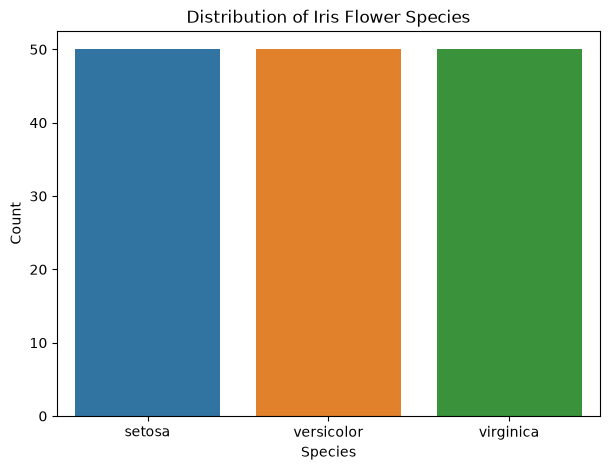

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="species", hue="species", legend=False)

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.show()

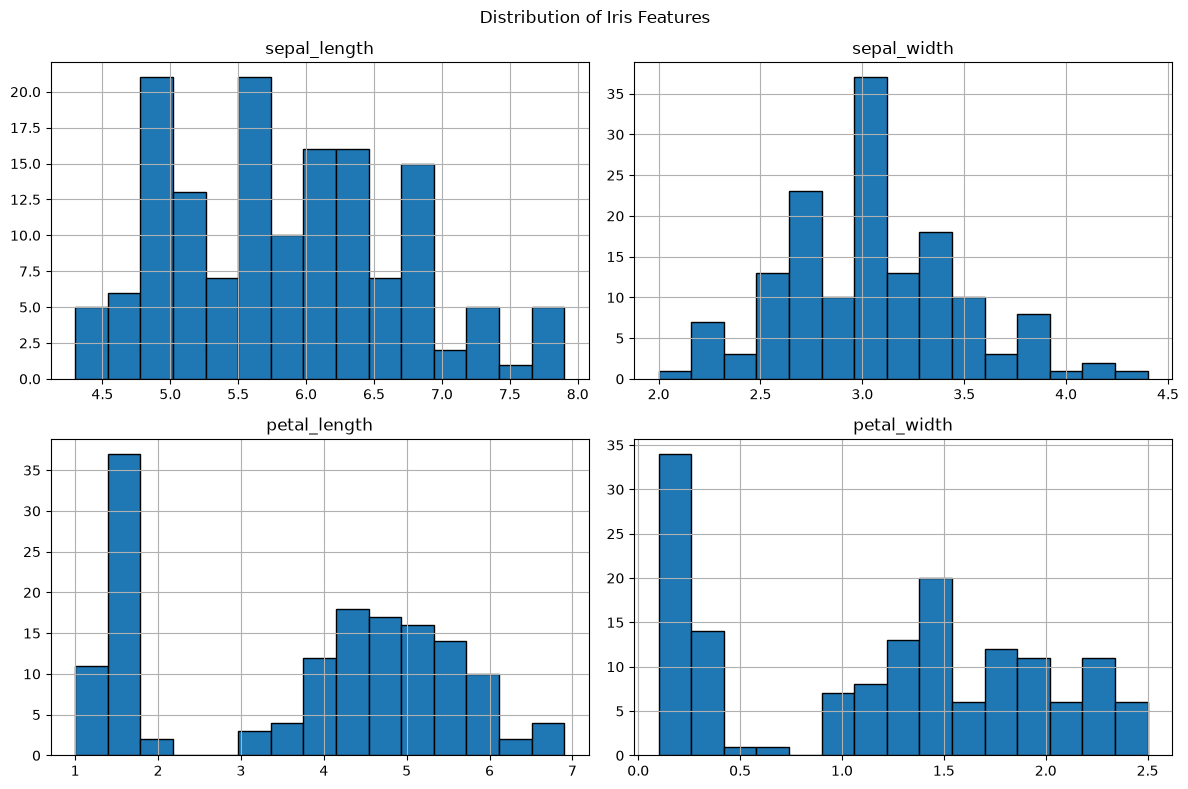

In [10]:
df.hist(figsize=(12, 8), bins=15, edgecolor="black")

plt.suptitle("Distribution of Iris Features")
plt.tight_layout()
plt.show()

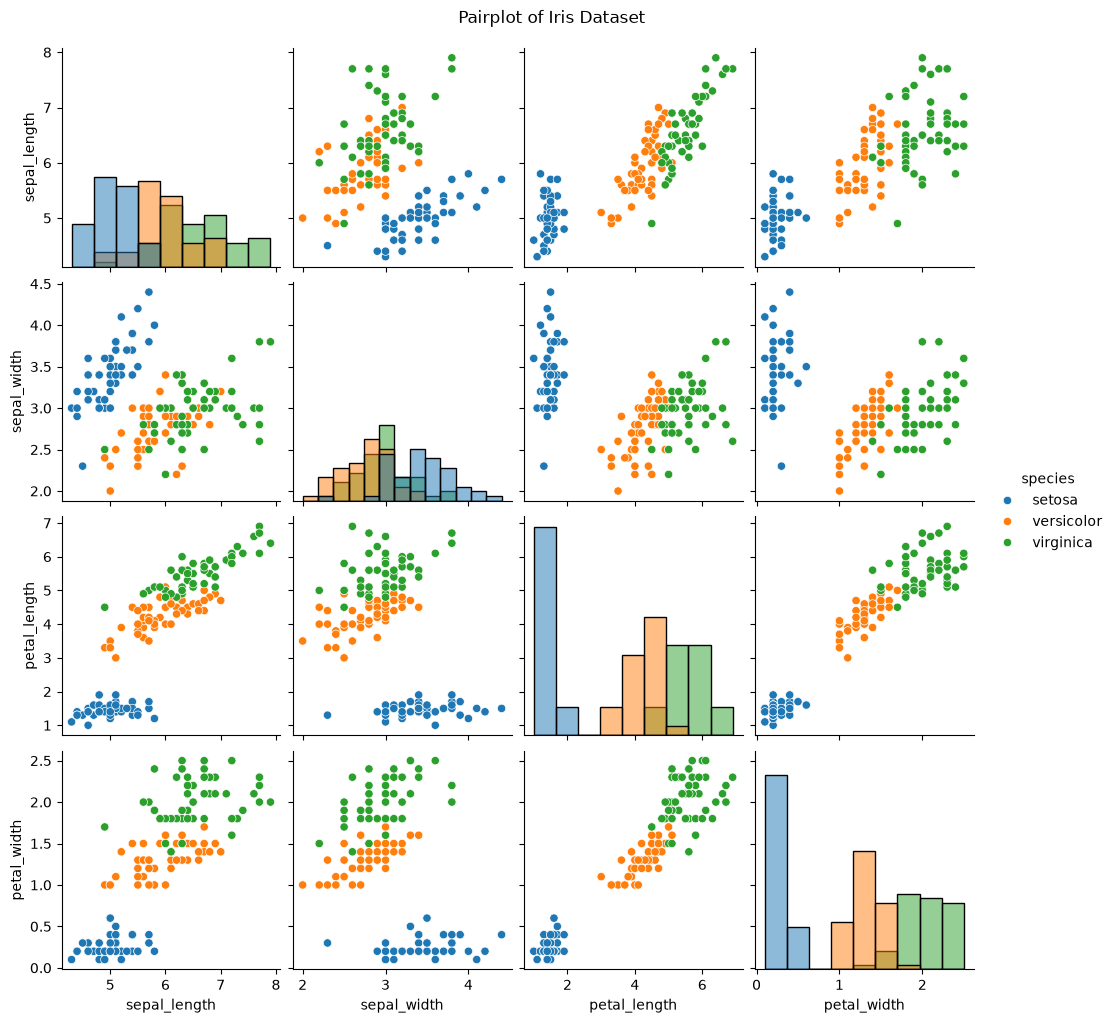

In [11]:
sns.pairplot(df, hue="species", diag_kind="hist")

plt.suptitle("Pairplot of Iris Dataset", y=1.02)

plt.show()

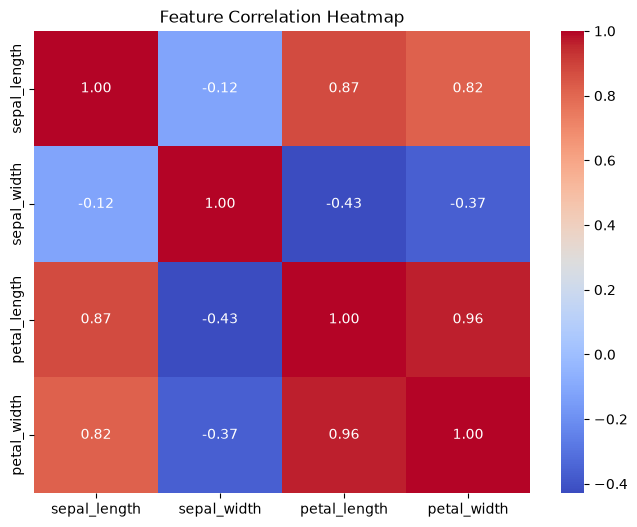

In [12]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [13]:
X = df.drop("species", axis=1)
y = df["species"]

print("Features:")
display(X.head())

print("Target:")
display(y.head())

Features:


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Target:


0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: str

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


In [15]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [16]:
print("Scaled training data:")
print(X_train_scaled[:5])

print("\nMean of scaled training features:")
print(X_train_scaled.mean(axis=0).round(2))

print("\nStandard deviation:")
print(X_train_scaled.std(axis=0).round(2))

Scaled training data:
[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]

Mean of scaled training features:
[-0.  0.  0.  0.]

Standard deviation:
[1. 1. 1. 1.]


In [17]:
logistic_model = LogisticRegression(random_state=42)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [18]:
y_pred_lr = logistic_model.predict(X_test_scaled)

print("Predicted values:")
print(y_pred_lr)

print("\nActual values:")
print(y_test.values)

Predicted values:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']

Actual values:
<StringArray>
[    'setosa',  'virginica', 'versicolor', 'versicolor',     'setosa',
 'versicolor',     'setosa',     'setosa',  'virginica', 'versicolor',
  'virginica',  'virginica',  'virginica', 'versicolor',     'setosa',
     'setosa',     'setosa', 'versicolor', 'versicolor',  'virginica',
     'setosa',  'virginica', 'versicolor',  'virginica',  'virginica',
 'versicolor', 'versicolor',     'setosa',  'virginica',     'setosa']
Length: 30, dtype: str


In [19]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr, average="weighted")
recall_lr = recall_score(y_test, y_pred_lr, average="weighted")
f1_lr = f1_score(y_test, y_pred_lr, average="weighted")

print("Logistic Regression Performance")
print("--------------------------------")
print("Accuracy:", round(accuracy_lr, 4))
print("Precision:", round(precision_lr, 4))
print("Recall:", round(recall_lr, 4))
print("F1-Score:", round(f1_lr, 4))

Logistic Regression Performance
--------------------------------
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1-Score: 0.9333


In [20]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



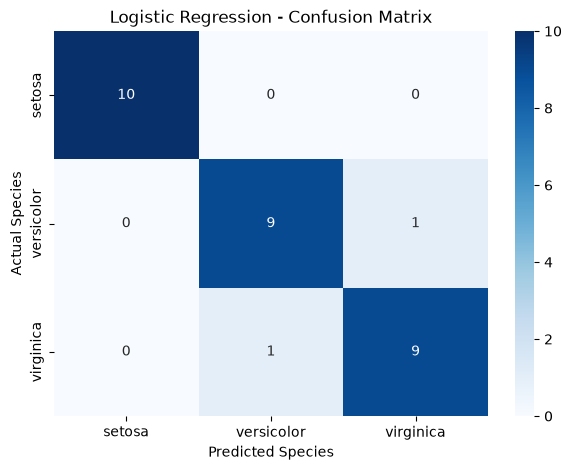

In [21]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=logistic_model.classes_,
    yticklabels=logistic_model.classes_
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

In [22]:
from sklearn.tree import DecisionTreeClassifier

In [23]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train_scaled, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [24]:
y_pred_dt = dt_model.predict(X_test_scaled)

print("Predicted values:")
print(y_pred_dt)

print("\nActual values:")
print(y_test.values)

Predicted values:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']

Actual values:
<StringArray>
[    'setosa',  'virginica', 'versicolor', 'versicolor',     'setosa',
 'versicolor',     'setosa',     'setosa',  'virginica', 'versicolor',
  'virginica',  'virginica',  'virginica', 'versicolor',     'setosa',
     'setosa',     'setosa', 'versicolor', 'versicolor',  'virginica',
     'setosa',  'virginica', 'versicolor',  'virginica',  'virginica',
 'versicolor', 'versicolor',     'setosa',  'virginica',     'setosa']
Length: 30, dtype: str


In [25]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt, average="weighted")
recall_dt = recall_score(y_test, y_pred_dt, average="weighted")
f1_dt = f1_score(y_test, y_pred_dt, average="weighted")

print("Decision Tree Performance")
print("--------------------------------")
print("Accuracy:", round(accuracy_dt, 4))
print("Precision:", round(precision_dt, 4))
print("Recall:", round(recall_dt, 4))
print("F1-Score:", round(f1_dt, 4))

Decision Tree Performance
--------------------------------
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1-Score: 0.9333


In [26]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



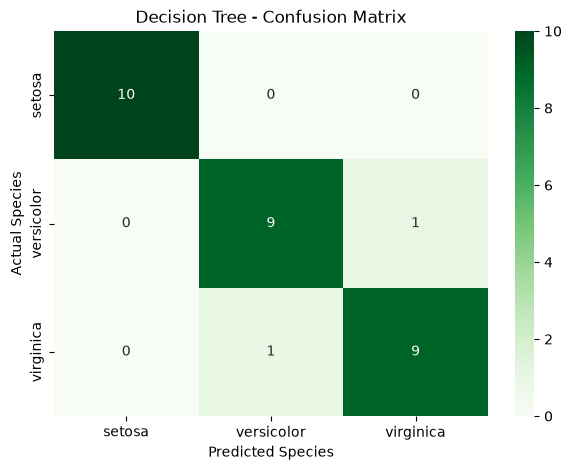

In [27]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=dt_model.classes_,
    yticklabels=dt_model.classes_
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

In [28]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [accuracy_lr, accuracy_dt],
    "Precision": [precision_lr, precision_dt],
    "Recall": [recall_lr, recall_dt],
    "F1-Score": [f1_lr, f1_dt]
})

display(results)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
1,Decision Tree,0.933333,0.933333,0.933333,0.933333


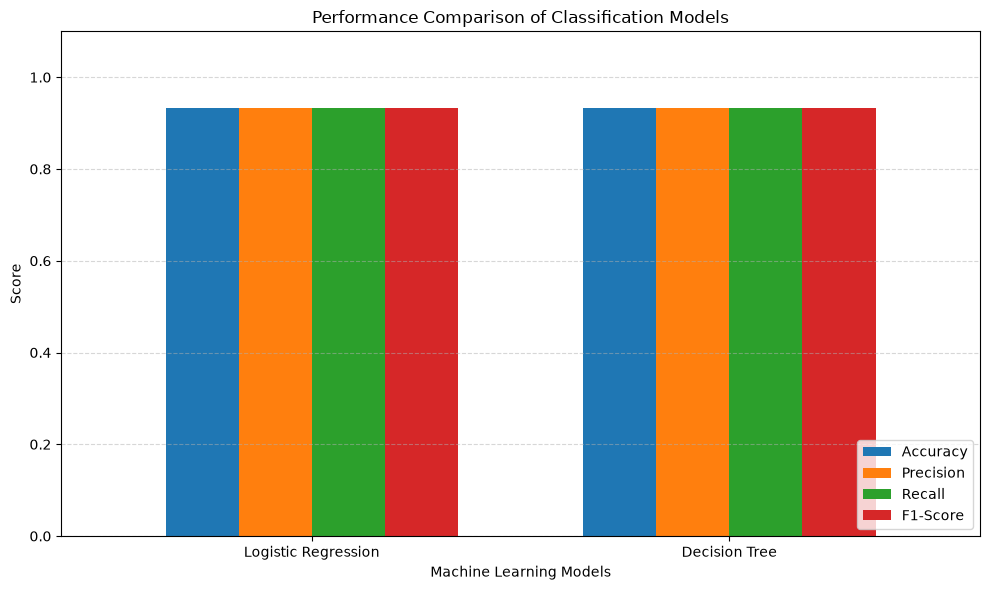

In [29]:
results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.1),
    width=0.7
)

plt.title("Performance Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

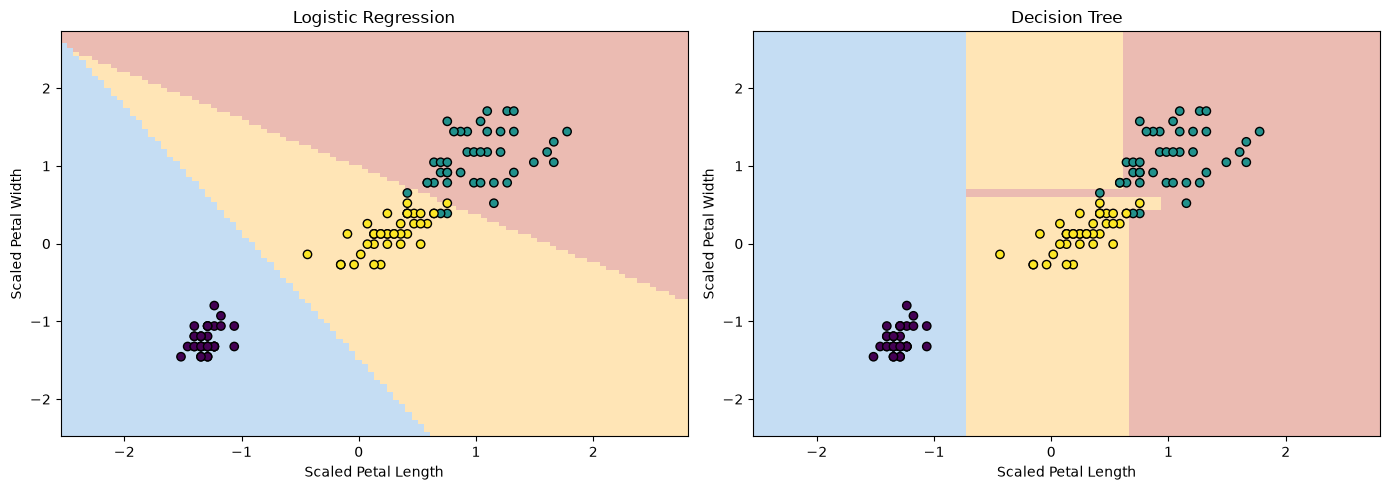

In [30]:
from sklearn.inspection import DecisionBoundaryDisplay

X_2d = df[["petal_length", "petal_width"]]
y_2d = df["species"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d,
    y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

scaler_2d = StandardScaler()

X2_train_scaled = scaler_2d.fit_transform(X2_train)

lr_2d = LogisticRegression(random_state=42)
dt_2d = DecisionTreeClassifier(random_state=42)

lr_2d.fit(X2_train_scaled, y2_train)
dt_2d.fit(X2_train_scaled, y2_train)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, title in zip(
    axes,
    [lr_2d, dt_2d],
    ["Logistic Regression", "Decision Tree"]
):
    DecisionBoundaryDisplay.from_estimator(
        model,
        X2_train_scaled,
        response_method="predict",
        plot_method="pcolormesh",
        alpha=0.3,
        ax=ax
    )

    ax.scatter(
        X2_train_scaled[:, 0],
        X2_train_scaled[:, 1],
        c=pd.factorize(y2_train)[0],
        edgecolor="black"
    )

    ax.set_title(title)
    ax.set_xlabel("Scaled Petal Length")
    ax.set_ylabel("Scaled Petal Width")

plt.tight_layout()
plt.show()

## Conclusion

In this project, I implemented supervised machine learning classification using the Iris dataset. I performed exploratory data analysis, handled feature scaling using StandardScaler, and divided the dataset into training and testing sets using an 80:20 ratio.

I trained two classification algorithms: Logistic Regression and Decision Tree Classifier. Both models achieved an accuracy of 93.33%, with identical precision, recall, and F1-scores.

I also evaluated the models using classification reports and confusion matrices and visualized their decision boundaries.

Through this project, I gained practical experience in data preprocessing, supervised learning, model evaluation, and data visualization using Python and Scikit-learn.